# AES Image Encryption Demo

 Compares ECB, CBC, CFB, and OFB modes by encrypting an image

In [1]:
# --- Imports ---
from cryptography.hazmat.primitives.ciphers import Cipher, algorithms, modes
from cryptography.hazmat.backends import default_backend
from cryptography.hazmat.primitives import padding as crypto_padding
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import os

In [2]:
# --- Helper function: load image ---
def load_image_as_bytes(path):
    """
    Load an image file, convert it to RGB, and return:
      - the numpy array of pixels
      - the raw RGB bytes
      - the (width, height) size
    """
    img = Image.open(path).convert("RGB")
    data = np.array(img)        # pixel data as numpy array
    return data, data.tobytes(), img.size


In [3]:
# AES block size = 128 bits = 16 bytes
BLOCK_SIZE = 16

# --- Padding ---
def pad_data(data):
    """
    Pad the input data to a multiple of 128 bits (16 bytes) 
    using PKCS7 padding (standard AES padding scheme).
    """
    padder = crypto_padding.PKCS7(128).padder()
    padded = padder.update(data) + padder.finalize()
    return padded

In [4]:
# --- AES encryption functions for different modes ---

def encrypt_ecb(data, key):
    """
    Encrypt data using AES in ECB mode.
    WARNING: ECB is insecure for structured data (patterns remain visible).
    """
    cipher = Cipher(algorithms.AES(key), modes.ECB(), backend=default_backend())
    encryptor = cipher.encryptor()
    padded_data = pad_data(data)
    ciphertext = encryptor.update(padded_data) + encryptor.finalize()
    return ciphertext

def encrypt_cbc(data, key, iv):
    """
    Encrypt data using AES in CBC mode.
    Safer than ECB: uses an IV to randomize the first block.
    """
    cipher = Cipher(algorithms.AES(key), modes.CBC(iv), backend=default_backend())
    encryptor = cipher.encryptor()
    padded_data = pad_data(data)
    ciphertext = encryptor.update(padded_data) + encryptor.finalize()
    return ciphertext

def encrypt_cfb(data, key, iv):
    """
    Encrypt data using AES in CFB mode.
    A stream-like mode, does not require padding.
    """
    cipher = Cipher(algorithms.AES(key), modes.CFB(iv), backend=default_backend())
    encryptor = cipher.encryptor()
    padded_data = pad_data(data)
    ciphertext = encryptor.update(padded_data) + encryptor.finalize()
    return ciphertext

def encrypt_ofb(data, key, iv):
    """
    Encrypt data using AES in OFB mode.
    Works like a stream cipher; also does not reveal patterns.
    """
    cipher = Cipher(algorithms.AES(key), modes.OFB(iv), backend=default_backend())
    encryptor = cipher.encryptor()
    padded_data = pad_data(data)
    ciphertext = encryptor.update(padded_data) + encryptor.finalize()
    return ciphertext

In [5]:
# --- Convert encrypted data back to image ---
def encrypted_bytes_to_image(enc_bytes, size):
    """
    Convert encrypted bytes back into an image of the same size.
    Any extra padding at the end is truncated.
    """
    pixel_count = size[0] * size[1] * 3  # 3 bytes per RGB pixel
    trimmed = enc_bytes[:pixel_count]
    arr = np.frombuffer(trimmed, dtype=np.uint8)
    return Image.fromarray(arr.reshape((size[1], size[0], 3)))

# --- Demo execution ---

In [6]:
# Load the input image (replace with your own test image)
image_path = "Norbert_Wiener.png"  
original_array, data_bytes, size = load_image_as_bytes(image_path)

# Generate a random AES key (128-bit) and IV
key = os.urandom(16)
iv = os.urandom(16)

# Encrypt the image data in each AES mode
ecb_encrypted = encrypt_ecb(data_bytes, key)
cbc_encrypted = encrypt_cbc(data_bytes, key, iv)
cfb_encrypted = encrypt_cfb(data_bytes, key, iv)
ofb_encrypted = encrypt_ofb(data_bytes, key, iv)

# Convert ciphertexts back into image format
ecb_img = encrypted_bytes_to_image(ecb_encrypted, size)
cbc_img = encrypted_bytes_to_image(cbc_encrypted, size)
cfb_img = encrypted_bytes_to_image(cfb_encrypted, size)
ofb_img = encrypted_bytes_to_image(ofb_encrypted, size)

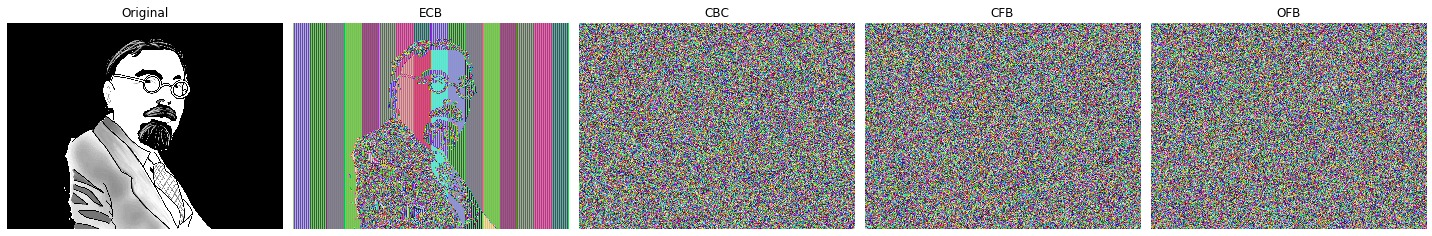

In [7]:
# --- Visualization ---
plt.figure(figsize=(20, 4))

plt.subplot(1, 5, 1)
plt.title("Original")
plt.imshow(original_array)
plt.axis('off')

plt.subplot(1, 5, 2)
plt.title("ECB")
plt.imshow(ecb_img)
plt.axis('off')

plt.subplot(1, 5, 3)
plt.title("CBC")
plt.imshow(cbc_img)
plt.axis('off')

plt.subplot(1, 5, 4)
plt.title("CFB")
plt.imshow(cfb_img)
plt.axis('off')

plt.subplot(1, 5, 5)
plt.title("OFB")
plt.imshow(ofb_img)
plt.axis('off')

plt.tight_layout()
plt.show()


# Decryption -given the encrypted image.

In [8]:
def unpad_data(data):
    unpadder = crypto_padding.PKCS7(128).unpadder()
    unpadded = unpadder.update(data) + unpadder.finalize()
    return unpadded


In [9]:
def decrypt_ecb(ciphertext, key):
    cipher = Cipher(algorithms.AES(key), modes.ECB(), backend=default_backend())
    decryptor = cipher.decryptor()
    padded_data = decryptor.update(ciphertext) + decryptor.finalize()
    return unpad_data(padded_data)

def decrypt_cbc(ciphertext, key, iv):
    cipher = Cipher(algorithms.AES(key), modes.CBC(iv), backend=default_backend())
    decryptor = cipher.decryptor()
    padded_data = decryptor.update(ciphertext) + decryptor.finalize()
    return unpad_data(padded_data)

def decrypt_cfb(ciphertext, key, iv):
    cipher = Cipher(algorithms.AES(key), modes.CFB(iv), backend=default_backend())
    decryptor = cipher.decryptor()
    padded_data = decryptor.update(ciphertext) + decryptor.finalize()
    return unpad_data(padded_data)

def decrypt_ofb(ciphertext, key, iv):
    cipher = Cipher(algorithms.AES(key), modes.OFB(iv), backend=default_backend())
    decryptor = cipher.decryptor()
    padded_data = decryptor.update(ciphertext) + decryptor.finalize()
    return unpad_data(padded_data)


In [10]:
def decrypted_bytes_to_image(plain_bytes, size):
    arr = np.frombuffer(plain_bytes[:size[0] * size[1] * 3], dtype=np.uint8)
    return Image.fromarray(arr.reshape((size[1], size[0], 3)))

In [11]:
ecb_decrypted = decrypt_ecb(ecb_encrypted, key)
cbc_decrypted = decrypt_cbc(cbc_encrypted, key, iv)
cfb_decrypted = decrypt_cfb(cfb_encrypted, key, iv)
ofb_decrypted = decrypt_ofb(ofb_encrypted, key, iv)

ecb_decrypted_img = decrypted_bytes_to_image(ecb_decrypted, size)
cbc_decrypted_img = decrypted_bytes_to_image(cbc_decrypted, size)
cfb_decrypted_img = decrypted_bytes_to_image(cfb_decrypted, size)
ofb_decrypted_img = decrypted_bytes_to_image(ofb_decrypted, size)


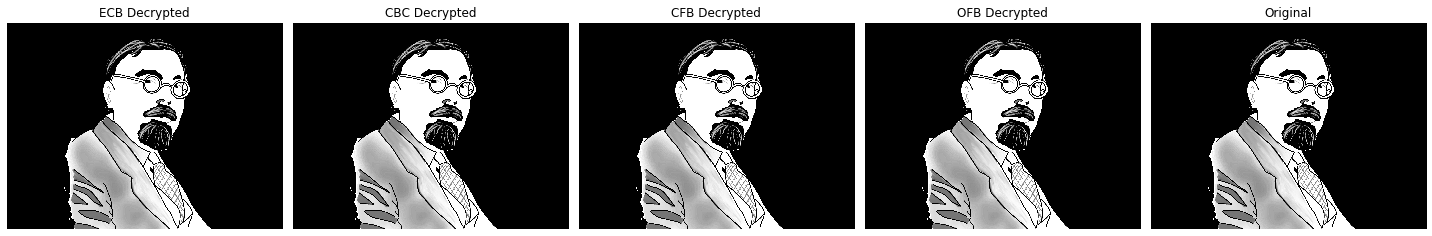

In [12]:
plt.figure(figsize=(20, 4))

plt.subplot(1, 5, 1)
plt.title("ECB Decrypted")
plt.imshow(ecb_decrypted_img)
plt.axis('off')

plt.subplot(1, 5, 2)
plt.title("CBC Decrypted")
plt.imshow(cbc_decrypted_img)
plt.axis('off')

plt.subplot(1, 5, 3)
plt.title("CFB Decrypted")
plt.imshow(cfb_decrypted_img)
plt.axis('off')

plt.subplot(1, 5, 4)
plt.title("OFB Decrypted")
plt.imshow(ofb_decrypted_img)
plt.axis('off')

plt.subplot(1, 5, 5)
plt.title("Original")
plt.imshow(original_array)
plt.axis('off')

plt.tight_layout()
plt.show()
